# Лекция 5: распределённый поток (Kafka + Spark) и RTAP — «алгоритм, который слушает мир»

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Лекция 5 (`docs/22_10_26_PREL_5_STREAMING DISTRIBUIT_RTAP`, PDF в папке к экзамену) переводит поток из ноутбука 04 (смоделирован на Python) в **настоящую распределённую систему**: Kafka собирает сообщения от многих источников, Spark Structured Streaming агрегирует их в окнах, алгоритм решает и объясняет решение, а на последнем шаге настройка и вердикт. В лекции источники — камеры, микрофон и датчики аудитории. У нас — **6 метеостанций Молдовы**: Кишинёв, Сороки, Бельцы, Унгены, Комрат, Кагул.

**Соответствие схеме RTAP из лекции (4 окна):**

| Окно лекции | Скрипт лекции | Наш компонент | Что делает |
|---|---|---|---|
| BAT1, BAT2 | `start_kafka_kraft.bat`, `create_topic_video_events.bat` | `rtap/kafka.sh start / topics / clean` | брокер Kafka 4.3 в режиме **KRaft** (без ZooKeeper, UUID кластера — один раз), топики |
| 1 — активация потоков | `kafka_trio_RTAP.py` | `rtap/producer_stations.py` | 6 станций = 6 независимых источников (потоков), JSON в топик `weather_events` (6 разделов, ключ — станция); ускоренное воспроизведение 2024–2025; внедрение неисправностей |
| 2 — агрегация | `spark_trio_RTAP.py` | `rtap/spark_aggregator.py` | **Spark 4.2 Structured Streaming**: окна по времени события (сутки) с watermark для опоздавших сообщений — региональная картина; окна по времени обработки (10 с, как в лекции) — пропускная способность; вывод в топик `rtap_agg` и CSV |
| 3 — решение | `alert_trio_RTAP.py` | `rtap/alert_service.py` | признаки → Random Forest + Elastic Net (второе мнение) → уровень тревоги + **SHAP**; региональный консенсус; контроль барометров и шума по соседям; восстановление пропусков; топик `rtap_alerts` + SQLite |
| 4 — вердикт и настройка | `verdict_trio_RTAP.py` | `rtap/verdict.py` + этот ноутбук + страница «RTAP» приложения | настройка C, l1_ratio, окна с кросс-валидацией по времени, «простая против настроенной», вердикт |

Оркестратор `rtap/run_pipeline.py` запускает окна в порядке лекции, каждое — **отдельным процессом**: брокер → топики → Spark → сервис тревог → станции. На macOS вместо `.bat` используются `.sh`; Kafka — из Homebrew, Spark — PySpark 4.2 на Java 21.

**Почему станции, а не камеры.** Идея лекции — «от личного присутствия к коллективному потоку» — у нас естественна: одна станция видит только свою точку, а 6 станций видят **атмосферный фронт**, который проходит над страной. В конце ноутбука проверяем, помогает ли этот коллективный контекст прогнозу.

In [1]:
import sys, json, subprocess, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "rtap")); sys.path.insert(0, str(ROOT / "src"))
from rtap_common import STATIONS, load_station_daily
from verdict import load_run, truth, station_metrics, tuning_experiment, REGIONAL_NAMES_RU
from db import load_dataset
from features import FEATURES, FEATURE_NAMES_RU, TARGET
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, average_precision_score

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
PY = str(ROOT / ".venv" / "bin" / "python")
RU_ST = STATIONS
THR = joblib.load(ROOT / "models" / "baseline_model.joblib")["threshold"]

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

def run(name, *args):
    t = time.time()
    p = subprocess.run([PY, str(ROOT / "rtap" / "run_pipeline.py"), "--out", name, *args], capture_output=True, text=True)
    print(p.stdout.strip()); print(p.stderr.strip()[-1500:]) if p.returncode else None
    print(f"[{name}] {time.time() - t:.0f} с")
    return load_run(name)

print(subprocess.run([str(ROOT / "rtap" / "kafka.sh"), "start"], capture_output=True, text=True).stdout.strip())
print(subprocess.run([str(ROOT / "rtap" / "kafka.sh"), "status"], capture_output=True, text=True).stdout.strip())

Broker is already running on localhost:9092


Broker: running on localhost:9092
Topic: weather_events	TopicId: 7lqmK7-pTze2W3Y58L9LXw	PartitionCount: 6	ReplicationFactor: 1	Configs: min.insync.replicas=1,segment.bytes=1073741824
Topic: rtap_alerts	TopicId: uM7H0IIeRGm8bDSmYD1ljQ	PartitionCount: 1	ReplicationFactor: 1	Configs: min.insync.replicas=1,segment.bytes=1073741824
Topic: __consumer_offsets	TopicId: XjfJvlLxRaCJYJMT1zEZxw	PartitionCount: 50	ReplicationFactor: 1	Configs: compression.type=producer,min.insync.replicas=1,cleanup.policy=compact,segment.bytes=104857600
Topic: rtap_agg	TopicId: u1t_LVT-SISqOHFkI2I-0A	PartitionCount: 1	ReplicationFactor: 1	Configs: min.insync.replicas=1,segment.bytes=1073741824


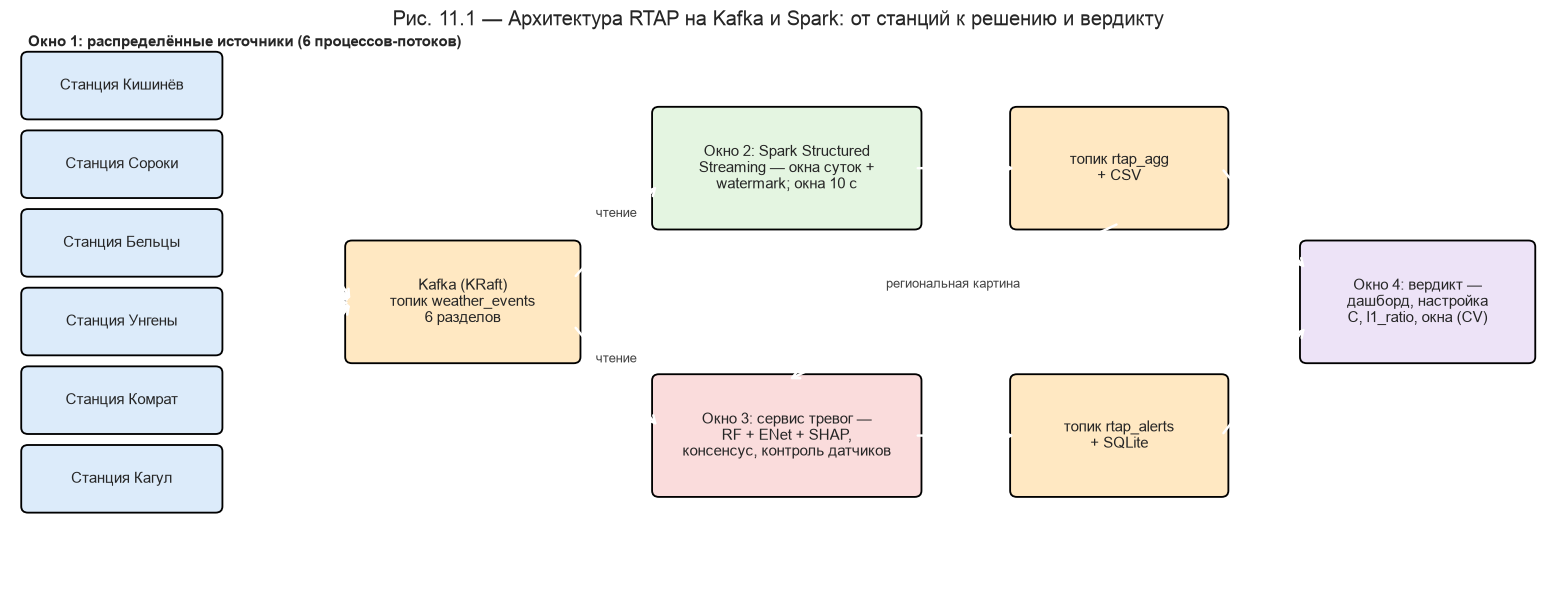

In [2]:
fig, ax = plt.subplots(figsize=(18, 6.5))
ax.set_xlim(0, 18); ax.set_ylim(0, 7); ax.axis("off")
def box(x, y, w, h, text, color):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="black", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9.5)
def arrow(x1, y1, x2, y2, text=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.6))
    if text: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.18, text, ha="center", fontsize=8.5, color="#444")
for i, s in enumerate(STATIONS.values()):
    box(0.2, 6.0 - i * 1.0, 2.2, 0.7, f"Станция {s}", "#DCEBFA")
    arrow(2.5, 6.35 - i * 1.0, 4.0, 3.6)
box(4.0, 2.9, 2.6, 1.4, "Kafka (KRaft)\nтопик weather_events\n6 разделов", "#FFE8C2")
box(7.6, 4.6, 3.0, 1.4, "Окно 2: Spark Structured\nStreaming — окна суток +\nwatermark; окна 10 с", "#E4F5E1")
box(7.6, 1.2, 3.0, 1.4, "Окно 3: сервис тревог —\nRF + ENet + SHAP,\nконсенсус, контроль датчиков", "#FADCDC")
box(11.8, 4.6, 2.4, 1.4, "топик rtap_agg\n+ CSV", "#FFE8C2")
box(11.8, 1.2, 2.4, 1.4, "топик rtap_alerts\n+ SQLite", "#FFE8C2")
box(15.2, 2.9, 2.6, 1.4, "Окно 4: вердикт —\nдашборд, настройка\nC, l1_ratio, окна (CV)", "#EDE3F7")
arrow(6.6, 3.9, 7.6, 5.1, "чтение"); arrow(6.6, 3.3, 7.6, 2.0, "чтение")
arrow(10.6, 5.3, 11.8, 5.3); arrow(10.6, 1.9, 11.8, 1.9); arrow(13.0, 4.6, 9.1, 2.6, "региональная картина")
arrow(14.2, 1.9, 15.2, 3.3); arrow(14.2, 5.3, 15.2, 4.0)
ax.text(0.2, 6.85, "Окно 1: распределённые источники (6 процессов-потоков)", fontsize=10, weight="bold")
ax.set_title("Рис. 11.1 — Архитектура RTAP на Kafka и Spark: от станций к решению и вердикту", fontsize=13)
save("fig_11_1_rtap_architecture")

---
# 1. Прогон «чистый»: 6 станций, 2024–2025, без неисправностей

730 суток × 6 станций; сутки воспроизводятся за 0.1 с (весь период — ~75 с реального времени), плюс 8 суток «прогрева» для лагов признаков. Первый вопрос — **корректность**: совпадают ли результаты потоковой системы с пакетным расчётом?
- агрегаты Spark против того же расчёта в pandas;
- прогнозы сервиса тревог для Кишинёва против прогнозов той же модели из ноутбука 02 (*training–serving skew*, как в ноутбуке 04).

In [3]:
clean = run("clean", "--start", "2024-01-01", "--end", "2025-12-31", "--speed", "0.1")
fc = clean["forecasts"]; fc = fc[fc.date >= "2024-01-01"]
print(fc.status.value_counts().to_string())

Окна 2 и 3 готовы за 6 с; запускаю 6 станций
Отправлено сообщений: 4434 за 73.8 с
  Кишинёв : вовремя 739, с опозданием 0, потеряно 0
  Сороки  : вовремя 739, с опозданием 0, потеряно 0
  Бельцы  : вовремя 739, с опозданием 0, потеряно 0
  Унгены  : вовремя 739, с опозданием 0, потеряно 0
  Комрат  : вовремя 739, с опозданием 0, потеряно 0
  Кагул   : вовремя 739, с опозданием 0, потеряно 0
Готово за 110 с (Spark: код 0, тревоги: код 0). Последние строки журнала тревог:
Сервис тревог готов за 5.5 с (разделов назначено: 7)
Обработано: 4435 записей станций, 739 региональных окон
[clean] 121 с


status
прогноз    4386


In [4]:
# 1) Spark aggregates vs pandas
daily = load_station_daily()
allp = pd.concat([d.assign(station=s) for s, d in daily.items()])
allp = allp[(allp.date >= "2024-01-01") & (allp.date <= "2025-12-31")]
truth_reg = allp.groupby(allp.date.dt.strftime("%Y-%m-%d")).agg(p=("pressure_msl_mean", "mean"),
                                                                 rs=("precipitation_sum", lambda x: (x >= 1).mean()), n=("station", "size"))
sr = clean["spark_regional"].assign(day=lambda d: d.window_start.str[:10]).set_index("day").join(truth_reg, how="inner")
print(f"Окон Spark: {len(clean['spark_regional'])}; с данными всех 6 станций: {(sr.n_messages == 6).sum()}")
print(f"Spark против pandas: max |Δ давление| = {(sr.pressure_mean - sr.p).abs().max():.1e} гПа, "
      f"max |Δ доля дождливых| = {(sr.rain_share - sr.rs).abs().max():.1e}")
# 2) streamed forecasts vs batch forecasts of the same model
rf = joblib.load(ROOT / "models" / "baseline_model.joblib")["model"]
data = load_dataset("chisinau"); test = data[data.date.dt.year >= 2024]
batch = pd.DataFrame({"date": test.date.dt.strftime("%Y-%m-%d"), "p_batch": rf.predict_proba(test[FEATURES])[:, 1]})
ch = fc[(fc.station == "chisinau") & fc.p_rain.notna()].merge(batch, on="date")
print(f"Кишинёв: поток против пакета — {len(ch)} дней, max |ΔP| = {(ch.p_rain - ch.p_batch).abs().max():.1e}")
m_clean = station_metrics(clean["forecasts"], THR)
m_clean.round(3)

Окон Spark: 739; с данными всех 6 станций: 731
Spark против pandas: max |Δ давление| = 4.5e-13 гПа, max |Δ доля дождливых| = 5.6e-17


Кишинёв: поток против пакета — 730 дней, max |ΔP| = 2.2e-16


,Станция,Прогнозов,ROC-AUC,F1,Recall,Precision
0,Бельцы,730,0.762,0.531,0.757,0.409
1,Кагул,730,0.790,0.501,0.759,0.374
2,Кишинёв,730,0.793,0.519,0.758,0.395
3,Комрат,730,0.771,0.468,0.713,0.348
4,Сороки,730,0.767,0.564,0.798,0.436
5,Унгены,730,0.762,0.510,0.734,0.391
6,все станции,4380,0.775,0.518,0.755,0.394


**Интерпретация (корректность).**

- **Распределённая система считает то же, что пакетный расчёт.** Агрегаты Spark по всем 731 суткам 2024–2025 (в каждом окне — все 6 станций) совпадают с pandas до 10⁻¹³ гПа. Прогнозы сервиса тревог для Кишинёва совпадают с прогнозами той же модели из ноутбука 02 до 2·10⁻¹⁶. Расхождения между обучением и эксплуатацией (*training–serving skew*) нет: признаки, собранные из потока сообщений Kafka, те же, что дал SQL-запрос хранилища.
- **Качество по станциям:** модель обучена только на Кишинёве, но на остальных станциях даёт ROC-AUC 0.762–0.790 (в целом 0.775, F1 0.518). Это подтверждает проверку географической справедливости из ноутбука 03 — уже в потоке. Кишинёв: ROC-AUC 0.793, F1 0.519 — ровно как в ноутбуке 02.

## 1.1 Окно 2: пропускная способность и задержка

Окна **по времени обработки** (10 с, как в лекции) показывают, сколько сообщений приходит от каждой станции. Задержка «станция → решение» — от отправки сообщения продюсером до записи прогноза сервисом тревог (без 8 суток прогрева: у этих записей по определению нет истории, и они 2 с ждут соседей, прежде чем получить пометку). Метрики микропачек Spark — из `progress.jsonl`.

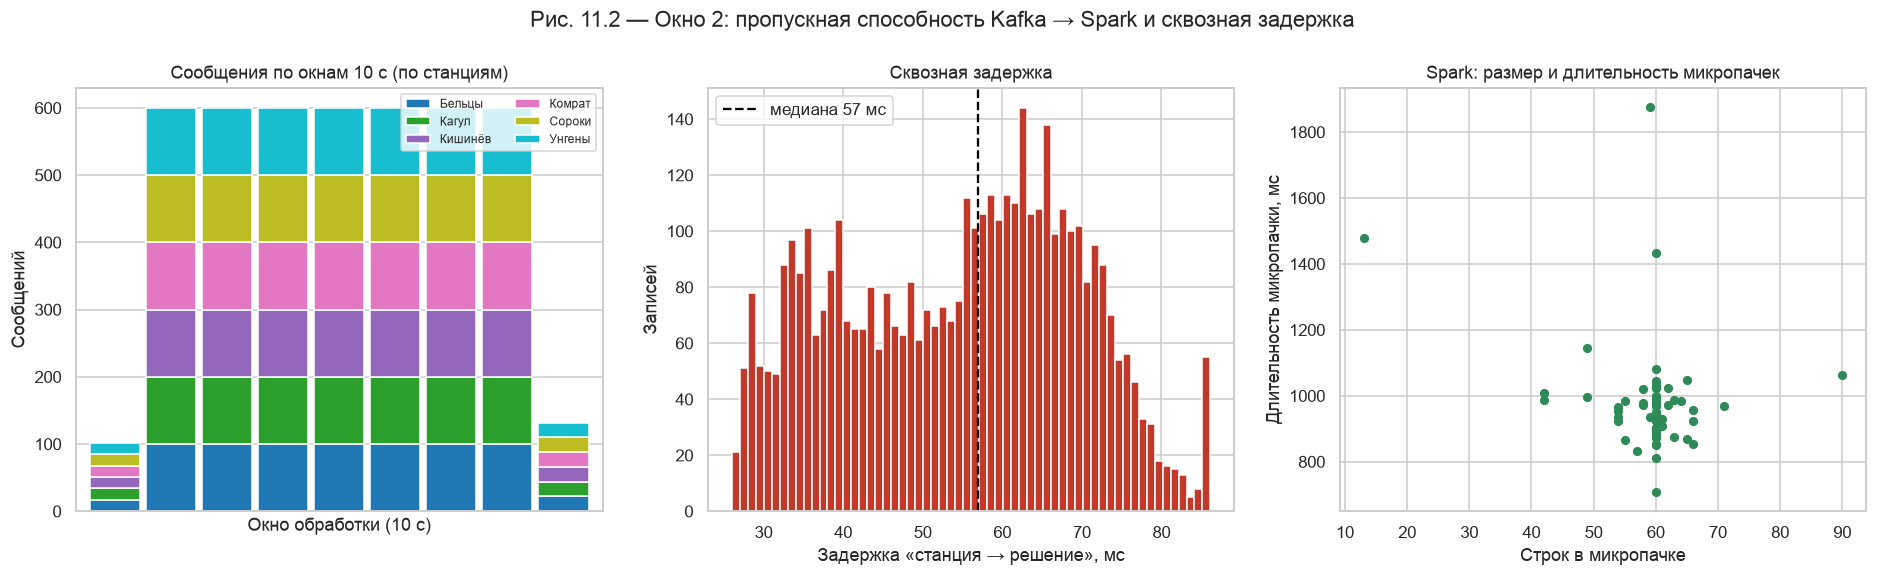

Сообщений в окне 10 с: медиана 600 (≈ 60 в секунду); задержка: медиана 57 мс, 95-й процентиль 77 мс; микропачек Spark с данными: 75, медиана 958 мс


In [5]:
tp, pr = clean["throughput"], clean["progress"]
fc_all = clean["forecasts"]
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
piv = tp.pivot_table(index="window_start", columns="station", values="n_messages", aggfunc="sum").fillna(0)
piv.index = range(len(piv))
piv.rename(columns=RU_ST).plot.bar(stacked=True, ax=axes[0], width=0.9, colormap="tab10")
axes[0].set(xlabel="Окно обработки (10 с)", ylabel="Сообщений", title="Сообщения по окнам 10 с (по станциям)")
axes[0].set_xticks([]); axes[0].legend(fontsize=8, ncol=2)
lat = fc_all[fc_all.date >= "2024-01-01"].latency_ms.dropna()   # warm-up records (no history by design) wait 2 s — excluded
axes[1].hist(lat.clip(upper=lat.quantile(0.99)), bins=60, color="#C0392B")
axes[1].axvline(lat.median(), color="black", ls="--", label=f"медиана {lat.median():.0f} мс")
axes[1].set(xlabel="Задержка «станция → решение», мс", ylabel="Записей", title="Сквозная задержка"); axes[1].legend()
reg = pr[(pr["query"] == "regional") & (pr.input_rows > 0)]
axes[2].scatter(reg.input_rows, reg.batch_ms, color="#2E8B57", s=25)
axes[2].set(xlabel="Строк в микропачке", ylabel="Длительность микропачки, мс", title="Spark: размер и длительность микропачек")
fig.suptitle("Рис. 11.2 — Окно 2: пропускная способность Kafka → Spark и сквозная задержка", y=1.02)
save("fig_11_2_throughput_latency")
per_win = piv.sum(axis=1)
print(f"Сообщений в окне 10 с: медиана {per_win.median():.0f} (≈ {per_win.median() / 10:.0f} в секунду); "
      f"задержка: медиана {lat.median():.0f} мс, 95-й процентиль {lat.quantile(0.95):.0f} мс; "
      f"микропачек Spark с данными: {len(reg)}, медиана {reg.batch_ms.median():.0f} мс")

## 1.2 Окно 3: региональный консенсус — тревога или рекомендация?

Вопрос RTAP из лекции: *«как отличить тревогу от рекомендации?»* и *«как разрешать конфликты распределённых источников?»*. Правило сервиса: жёлтый код одной станции — **рекомендация**; если дождь ожидают **≥ 4 из 6 станций**, это **региональная тревога**. Проверяем, оправдано ли такое различие: что на самом деле происходило на следующий день.

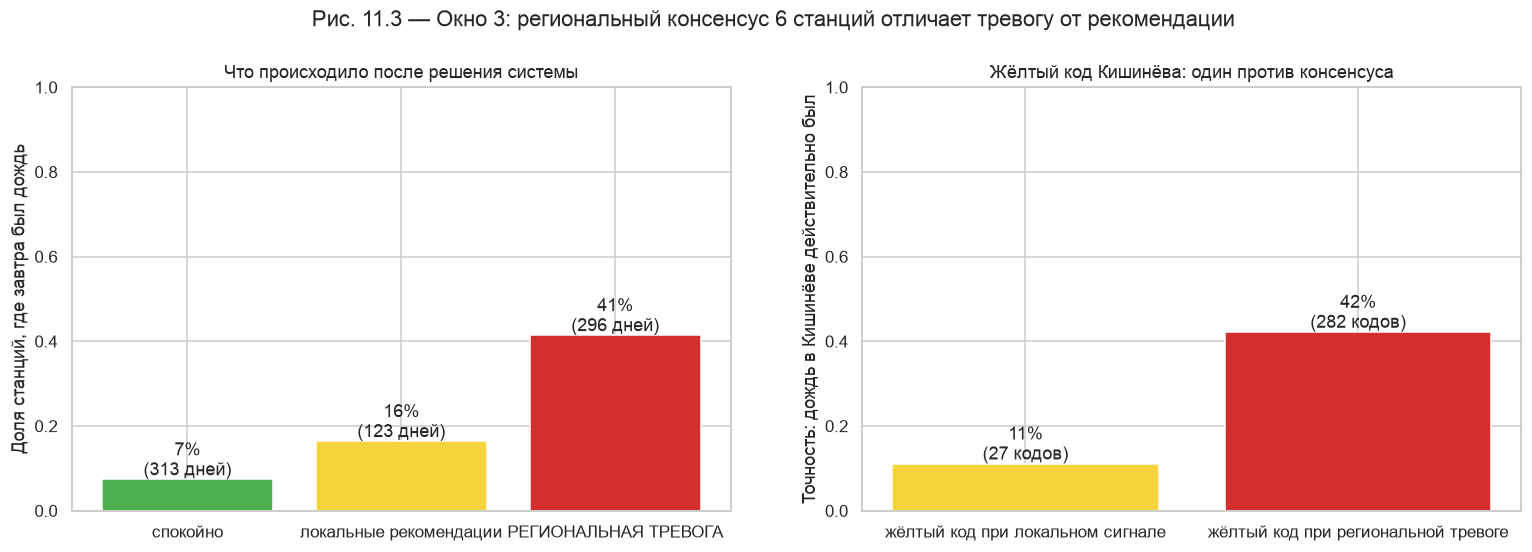

,Дней,Доля станций с дождём завтра,Дождь в Кишинёве завтра,Жёлтых кодов Кишинёва,Точность (дождь был)
Решение,,,,,
спокойно,313,0.074,0.058,NaN,NaN
локальные рекомендации,123,0.164,0.154,27.0,0.111
РЕГИОНАЛЬНАЯ ТРЕВОГА,296,0.414,0.420,282.0,0.422


In [6]:
regd = clean["regional"].copy()
regd["Решение"] = regd.decision.str.replace(r" \(неполные.*", "", regex=True)
tr = truth()
share_next = tr[tr.date >= "2024-01-01"].groupby("date").rain_tomorrow.mean().rename("Доля станций с дождём завтра")
chis_next = tr[tr.station == "chisinau"].set_index("date").rain_tomorrow.rename("Дождь в Кишинёве завтра")
regd = regd.join(share_next, on="date").join(chis_next, on="date")
summary_reg = regd.groupby("Решение").agg(Дней=("date", "size"), **{"Доля станций с дождём завтра": ("Доля станций с дождём завтра", "mean"),
                                                                     "Дождь в Кишинёве завтра": ("Дождь в Кишинёве завтра", "mean")})
fc_ch = fc[(fc.station == "chisinau") & fc.p_rain.notna()].merge(regd[["date", "Решение"]], on="date").merge(
    tr[tr.station == "chisinau"][["date", "rain_tomorrow"]], on="date").dropna(subset=["rain_tomorrow"])
yellow = fc_ch[fc_ch.p_rain >= THR]
prec = yellow.groupby("Решение").rain_tomorrow.agg(["size", "mean"]).rename(columns={"size": "Жёлтых кодов Кишинёва", "mean": "Точность (дождь был)"})
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
order = ["спокойно", "локальные рекомендации", "РЕГИОНАЛЬНАЯ ТРЕВОГА"]
s = summary_reg.reindex(order)
axes[0].bar(range(3), s["Доля станций с дождём завтра"], color=["#4CAF50", "#F5D33B", "#D32F2F"])
for i, (n, v) in enumerate(zip(s["Дней"], s["Доля станций с дождём завтра"])):
    axes[0].text(i, v + 0.01, f"{v:.0%}\n({n} дней)", ha="center")
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(order)
axes[0].set(ylabel="Доля станций, где завтра был дождь", title="Что происходило после решения системы", ylim=(0, 1))
p = prec.reindex(order[1:])
axes[1].bar(range(2), p["Точность (дождь был)"], color=["#F5D33B", "#D32F2F"])
for i, (n, v) in enumerate(zip(p["Жёлтых кодов Кишинёва"], p["Точность (дождь был)"])):
    axes[1].text(i, v + 0.01, f"{v:.0%}\n({n} кодов)", ha="center")
axes[1].set_xticks(range(2)); axes[1].set_xticklabels(["жёлтый код при локальном сигнале", "жёлтый код при региональной тревоге"])
axes[1].set(ylabel="Точность: дождь в Кишинёве действительно был", title="Жёлтый код Кишинёва: один против консенсуса", ylim=(0, 1))
fig.suptitle("Рис. 11.3 — Окно 3: региональный консенсус 6 станций отличает тревогу от рекомендации", y=1.02)
save("fig_11_3_regional_consensus")
pd.concat([summary_reg.reindex(order), prec.reindex(order)], axis=1).round(3)

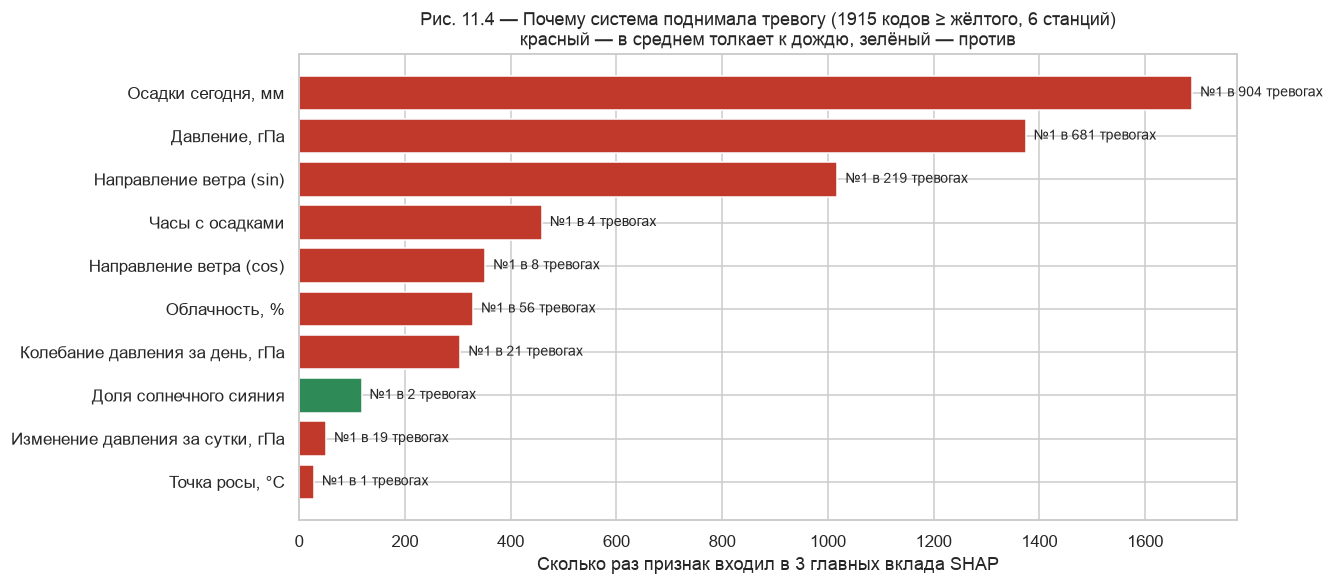

[Кагул, 2024-09-11] ОРАНЖЕВЫЙ КОД на 12.09.2024: P(осадки) = 76%, P(критическая погода) = 57%. Причины: давление упало на 12.4 гПа за 3 дня; низкое давление (1007 гПа); сплошная облачность (96 %); воздух близок к насыщению; ветер восточного–южного направления (влажный воздух). Отложите полевые работы и мероприятия на открытом воздухе; подготовьте аварийные службы.
   SHAP: [{"признак": "Осадки сегодня, мм", "вклад": 0.117}, {"признак": "Давление, гПа", "вклад": 0.104}, {"признак": "Направление ветра (sin)", "вклад": 0.06}]

[Кишинёв, 2024-09-11] КРАСНЫЙ КОД на 12.09.2024: P(осадки) = 75%, P(критическая погода) = 65%. Причины: давление упало на 12.6 гПа за 3 дня; низкое давление (1007 гПа); сплошная облачность (88 %); ветер восточного–южного направления (влажный воздух). Введите план действий в чрезвычайной ситуации; оповестите население; избегайте лишних поездок.
   SHAP: [{"признак": "Осадки сегодня, мм", "вклад": 0.112}, {"признак": "Давление, гПа", "вклад": 0.104}, {"признак": "Напр

In [7]:
# SHAP in the alerts: which features explain the yellow/orange/red codes of all stations
al = fc[(fc.level >= 1)]
top = pd.Series([t["признак"] for js in al.shap for t in json.loads(js)]).value_counts()
first = pd.Series([json.loads(js)[0]["признак"] for js in al.shap if json.loads(js)]).value_counts()
sign = pd.DataFrame([t for js in al.shap for t in json.loads(js)]).groupby("признак")["вклад"].mean()
fig, ax = plt.subplots(figsize=(11, 5.5))
t10 = top.head(10)[::-1]
ax.barh(t10.index, t10.values, color=["#C0392B" if sign[f] > 0 else "#2E8B57" for f in t10.index])
for y_, f in enumerate(t10.index):
    ax.text(t10[f], y_, f"  №1 в {first.get(f, 0)} тревогах", va="center", fontsize=9)
ax.set(xlabel="Сколько раз признак входил в 3 главных вклада SHAP", title=f"Рис. 11.4 — Почему система поднимала тревогу ({len(al)} кодов ≥ жёлтого, 6 станций)\nкрасный — в среднем толкает к дождю, зелёный — против")
save("fig_11_4_alert_shap")
ex = al[al.level >= 2].sort_values("p_rain", ascending=False).head(3)
for _, r in ex.iterrows():
    print(f"[{RU_ST[r.station]}, {r.date}] {r.message}\n   SHAP: {r.shap}\n")

**Интерпретация (окна 2–3, чистый прогон).**

**Окно 2 — пропускная способность и задержка (рис. 11.2).**
- В окне обработки 10 с приходит около 600 сообщений (≈ 60 в секунду: 6 станций × 10 суток в секунду ускоренного времени).
- Сквозная задержка «станция → решение с SHAP»: медиана **57 мс**, 95-й процентиль 77 мс.
- Микропачка Spark обрабатывается в среднем за 958 мс; при обработке раз в секунду это означает, что Spark успевает.
- Для реальной станции (одна запись в сутки) запас огромный. Предел системы виден в упражнении A.

**Окно 3 — тревога или рекомендация (рис. 11.3).** Региональный консенсус надёжно различает ситуации:
- в «спокойные» дни (313) назавтра дождь был лишь на 7 % станций;
- при «локальных рекомендациях» (123 дня) — на 16 %;
- при **региональной тревоге** (296 дней) — на **41 %**.

Главное для Кишинёва: его жёлтый код при **региональной тревоге** верен в **42 %** случаев (282 кода), а одиночный жёлтый код без поддержки соседей — лишь в **11 %** (27 кодов). Это и есть ответ на вопросы лекции «как отличить тревогу от рекомендации» и «как разрешать конфликты источников»: одиночный сигнал вчетверо менее надёжен. Его стоит выдавать как рекомендацию, а тревогу — по согласию большинства станций.

**SHAP в тревогах (рис. 11.4).** Из 1 915 кодов ≥ жёлтого по 6 станциям главным вкладом SHAP чаще всего были **осадки сегодня** (№ 1 в 904 тревогах), **давление** (681) и **восточная составляющая ветра** (219). Облачность и колебание давления обычно усиливают, но не задают решение. Физическая картина «идёт дождь, давление низкое, ветер с востока — юга» одинакова на всех станциях. Каждое сообщение содержит три главных вклада SHAP и причины простым языком. Пример — 11.09.2024: красный код в Кишинёве, оранжевый в Кагуле, вклады «осадки сегодня» (+0.11), «давление» (+0.10), «восточный ветер» (+0.06). Код **оправдался**: 12.09 в Кишинёве выпало 16.5 мм (выше критического порога 10 мм), сильные осадки были на 5 станциях из 6. На следующий день та же картина дала **ложную тревогу**, разобранную в ноутбуке 08 (прогноз на 13.09, выпало 0.4 мм). Ливень закончился, но признаки ещё «помнили» его, а вчерашний дождь — главный вклад SHAP. Поток показывает обе стороны одного и того же правила модели.

---
# 2. Прогон с неисправностями: обнаружить → смоделировать → снизить

Лекция RTAP требует **постоянно отслеживать bias и noise**. В поток внесены 5 неисправностей (система о них не знает):

| Неисправность | Станция | Когда | Что должна сделать система |
|---|---|---|---|
| смещение барометра +6 гПа (bias) | Кишинёв | с 01.07.2024 | найти по соседям, оценить, вычитать |
| гауссов шум 0.75σ на 4 датчиках (noise) | Бельцы | 01.09–31.10.2024 | индекс шума → снизить доверие |
| 5 % сообщений опаздывают на 3 суток | Кагул | весь период | watermark Spark + восстановление по соседям |
| 2 % сообщений теряются | Комрат | весь период | контроль полноты окон + восстановление |
| станция перестаёт присылать направление ветра | Унгены | с 01.03.2025 | взять поле у соседей того же дня |

Тот же прогон повторён **без автокоррекции барометра**, чтобы измерить её эффект.

**Калибровка индекса шума (сделали X, потому что Y).** В первом варианте порог индекса шума был 1.4, и на **исправных** данных система регулярно объявляла «датчики шумят» (217 прогнозов с пониженным доверием в чистом прогоне): естественная изменчивость погоды за 14 дней иногда сама даёт индекс 1.4–1.8. Поэтому порог выбран по распределению индекса на исправных данных 2015–2022 (6 станций, проверка раз в неделю) и на внесённом шуме: включение при **1.8** (≈ максимум на исправных данных), выключение ниже **1.3** (95-й процентиль) — гистерезис против «мигания».

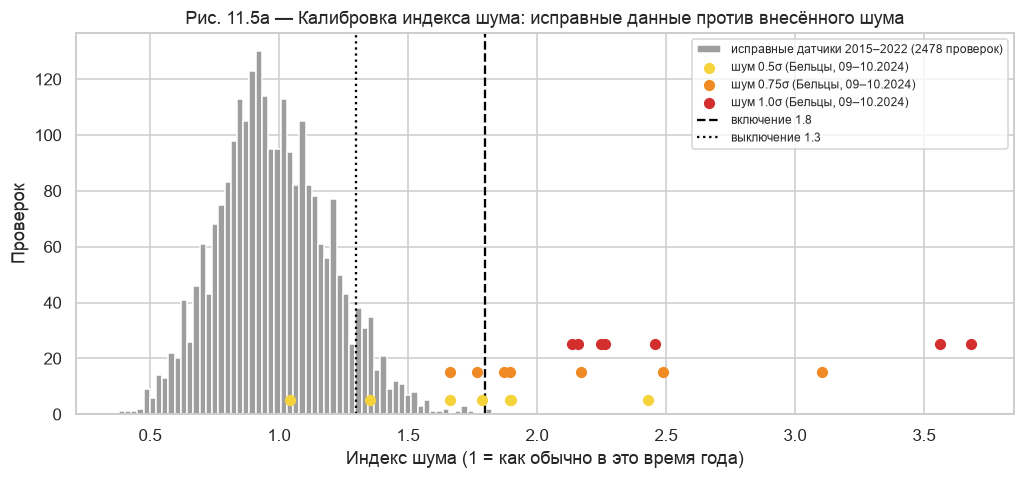

Исправные данные: 95-й процентиль 1.35, 99-й 1.52, максимум 1.83; доля выше порога включения: 0.08%
{'шум 0.5σ': [2.43, 1.89, 1.79, 1.9, 1.66, 1.04, 1.35], 'шум 0.75σ': [3.11, 2.49, 1.87, 2.17, 1.9, 1.66, 1.77], 'шум 1.0σ': [3.68, 3.56, 2.25, 2.46, 2.26, 2.14, 2.16]}


In [8]:
from alert_service import noise_reference, NOISE_SENSORS, NOISE_ON, NOISE_OFF
from regularization import add_sensor_noise
ref = noise_reference(daily)
def weekly_index(d, st, start, end):
    d = d.set_index("date").sort_index(); out = []
    for day in pd.date_range(start, end, freq="W-MON"):
        h = d.loc[day - pd.Timedelta(days=14):day].reset_index()
        if len(h) < 14: continue
        r = ref[st].loc[h.date.dt.dayofyear.clip(upper=365)].mean()
        out.append(np.median([h[c].diff().abs().median() / r[c] for c in NOISE_SENSORS]))
    return np.array(out)
idx_clean = np.concatenate([weekly_index(daily[s], s, "2015-02-01", "2022-12-31") for s in daily])
idx_noise = {sg: weekly_index(add_sensor_noise(daily["balti"], sensors=NOISE_SENSORS, sigma=sg, start="2024-09-01", end="2024-10-31"),
                              "balti", "2024-09-15", "2024-10-31") for sg in (0.5, 0.75, 1.0)}
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(idx_clean, bins=60, color="#9E9E9E", label=f"исправные датчики 2015–2022 ({len(idx_clean)} проверок)")
for sg, col in zip(idx_noise, ["#F5D33B", "#F08A24", "#D32F2F"]):
    ax.scatter(idx_noise[sg], np.full(len(idx_noise[sg]), 5 + 10 * list(idx_noise).index(sg)), color=col, s=40, zorder=3, label=f"шум {sg}σ (Бельцы, 09–10.2024)")
ax.axvline(NOISE_ON, color="black", ls="--", label=f"включение {NOISE_ON}"); ax.axvline(NOISE_OFF, color="black", ls=":", label=f"выключение {NOISE_OFF}")
ax.set(xlabel="Индекс шума (1 = как обычно в это время года)", ylabel="Проверок", title="Рис. 11.5а — Калибровка индекса шума: исправные данные против внесённого шума")
ax.legend(fontsize=8)
save("fig_11_5a_noise_calibration")
print(f"Исправные данные: 95-й процентиль {np.quantile(idx_clean, .95):.2f}, 99-й {np.quantile(idx_clean, .99):.2f}, максимум {idx_clean.max():.2f}; "
      f"доля выше порога включения: {(idx_clean > NOISE_ON).mean():.2%}")
print({f"шум {k}σ": np.round(v, 2).tolist() for k, v in idx_noise.items()})

In [9]:
FAULTS = ["--start", "2024-01-01", "--end", "2025-12-31", "--speed", "0.1", "--bias", "chisinau:6:2024-07-01",
          "--noise", "balti:0.75:2024-09-01:2024-10-31", "--late", "cahul:0.05:3", "--drop", "comrat:0.02",
          "--drop-field", "ungheni:wind_direction_10m_dominant:2025-03-01"]
faults = run("faults", *FAULTS)
nocorr = run("faults_nocorr", *FAULTS, "--no-correct")
sens = faults["sensor"]
print(sens[sens.check_name != "полнота"][["date", "station", "check_name", "value", "message"]].to_string())
print(f"\nКонтроль полноты: окон Spark с данными не от всех станций — {(sens.check_name == 'полнота').sum()}")
print(faults["forecasts"].query("date >= '2024-01-01'").status.str.replace(r"дополнено по соседям: [^)]*", "дополнено по соседям", regex=True).value_counts().to_string())
dropped = faults["progress"].query("query == 'regional'").dropped_by_watermark.sum()
print(f"Spark: строк, отброшенных watermark (опоздали больше чем на 2 суток): {dropped}")

Окна 2 и 3 готовы за 6 с; запускаю 6 станций
Отправлено сообщений: 4416 за 73.8 с
  Кишинёв : вовремя 739, с опозданием 0, потеряно 0
  Сороки  : вовремя 739, с опозданием 0, потеряно 0
  Бельцы  : вовремя 739, с опозданием 0, потеряно 0
  Унгены  : вовремя 739, с опозданием 0, потеряно 0
  Комрат  : вовремя 721, с опозданием 0, потеряно 18
  Кагул   : вовремя 702, с опозданием 37, потеряно 0
Готово за 110 с (Spark: код 0, тревоги: код 0). Последние строки журнала тревог:
Сервис тревог готов за 5.5 с (разделов назначено: 7)
Обработано: 4417 записей станций, 739 региональных окон
[faults] 121 с


Окна 2 и 3 готовы за 6 с; запускаю 6 станций
Отправлено сообщений: 4416 за 73.8 с
  Кишинёв : вовремя 739, с опозданием 0, потеряно 0
  Сороки  : вовремя 739, с опозданием 0, потеряно 0
  Бельцы  : вовремя 739, с опозданием 0, потеряно 0
  Унгены  : вовремя 739, с опозданием 0, потеряно 0
  Комрат  : вовремя 721, с опозданием 0, потеряно 18
  Кагул   : вовремя 702, с опозданием 37, потеряно 0
Готово за 110 с (Spark: код 0, тревоги: код 0). Последние строки журнала тревог:
Сервис тревог готов за 5.5 с (разделов назначено: 7)
Обработано: 4417 записей станций, 739 региональных окон
[faults_nocorr] 121 с


         date   station check_name     value                                                                                                                  message
2  2024-07-05  chisinau   барометр  6.000000  барометр станции Кишинёв отклоняется от соседей на +6.0 гПа 5 дней подряд (с 01.07) — включена автоматическая коррекция
4  2024-09-16     balti        шум  1.945395                                  датчики станции Бельцы шумят: индекс шума 1.9 (обычно ≈ 1) — доверие к прогнозу снижено
5  2024-11-11     balti        шум  0.904171                                                                    датчики станции Бельцы снова в норме: индекс шума 0.9

Контроль полноты: окон Spark с данными не от всех станций — 18
status
прогноз                                    3917
прогноз (дополнено по соседям)              358
прогноз (шум датчиков: доверие снижено)      56
прогноз (опоздавшая запись)                  37
Spark: строк, отброшенных watermark (опоздали больше чем на 2 суток): 0


In [10]:
def period_metrics(res, station, start, end, col="p_rain"):
    f = res["forecasts"]
    f = f[(f.station == station) & (f.date >= start) & (f.date <= end) & f[col].notna()].merge(truth(), on=["station", "date"]).dropna(subset=["rain_tomorrow"])
    y, p = f.rain_tomorrow.astype(int), f[col]
    return {"ROC-AUC": roc_auc_score(y, p), "F1": f1_score(y, p >= THR), "Recall": recall_score(y, p >= THR),
            "Precision": precision_score(y, p >= THR), "Средняя P": p.mean(), "Дней": len(f)}
rows = []
for name, res in [("исправные датчики", clean), ("неисправности + автокоррекция", faults), ("неисправности без коррекции", nocorr)]:
    rows.append({"Случай": "Кишинёв, барометр +6 гПа (07.2024–12.2025)", "Прогон": name, **period_metrics(res, "chisinau", "2024-07-01", "2025-12-31")})
for name, res in [("исправные датчики", clean), ("с шумом", faults)]:
    rows.append({"Случай": "Бельцы, шум 0.75σ (09–10.2024), RF", "Прогон": name, **period_metrics(res, "balti", "2024-09-01", "2024-10-31")})
    rows.append({"Случай": "Бельцы, шум 0.75σ (09–10.2024), ENet", "Прогон": name, **period_metrics(res, "balti", "2024-09-01", "2024-10-31", "p_rain_enet")})
for name, res in [("исправные датчики", clean), ("поле восстановлено по соседям", faults)]:
    rows.append({"Случай": "Унгены без направления ветра (03–12.2025)", "Прогон": name, **period_metrics(res, "ungheni", "2025-03-01", "2025-12-31")})
impact = pd.DataFrame(rows)
impact.round(3)

,Случай,Прогон,ROC-AUC,F1,Recall,Precision,Средняя P,Дней
0,"Кишинёв, барометр +6 гПа (07.2024–12.2025)",исправные датчики,0.787,0.501,0.724,0.384,0.229,548
1,"Кишинёв, барометр +6 гПа (07.2024–12.2025)",неисправности + автокоррекция,0.789,0.495,0.707,0.381,0.225,548
2,"Кишинёв, барометр +6 гПа (07.2024–12.2025)",неисправности без коррекции,0.779,0.498,0.629,0.412,0.192,548
3,"Бельцы, шум 0.75σ (09–10.2024), RF",исправные датчики,0.919,0.727,1.000,0.571,0.251,61
4,"Бельцы, шум 0.75σ (09–10.2024), ENet",исправные датчики,0.887,0.500,1.000,0.333,0.447,61
5,"Бельцы, шум 0.75σ (09–10.2024), RF",с шумом,0.886,0.667,0.938,0.517,0.271,61
6,"Бельцы, шум 0.75σ (09–10.2024), ENet",с шумом,0.846,0.492,1.000,0.327,0.448,61
7,Унгены без направления ветра (03–12.2025),исправные датчики,0.774,0.561,0.779,0.438,0.243,305
8,Унгены без направления ветра (03–12.2025),поле восстановлено по соседям,0.778,0.558,0.779,0.435,0.245,305


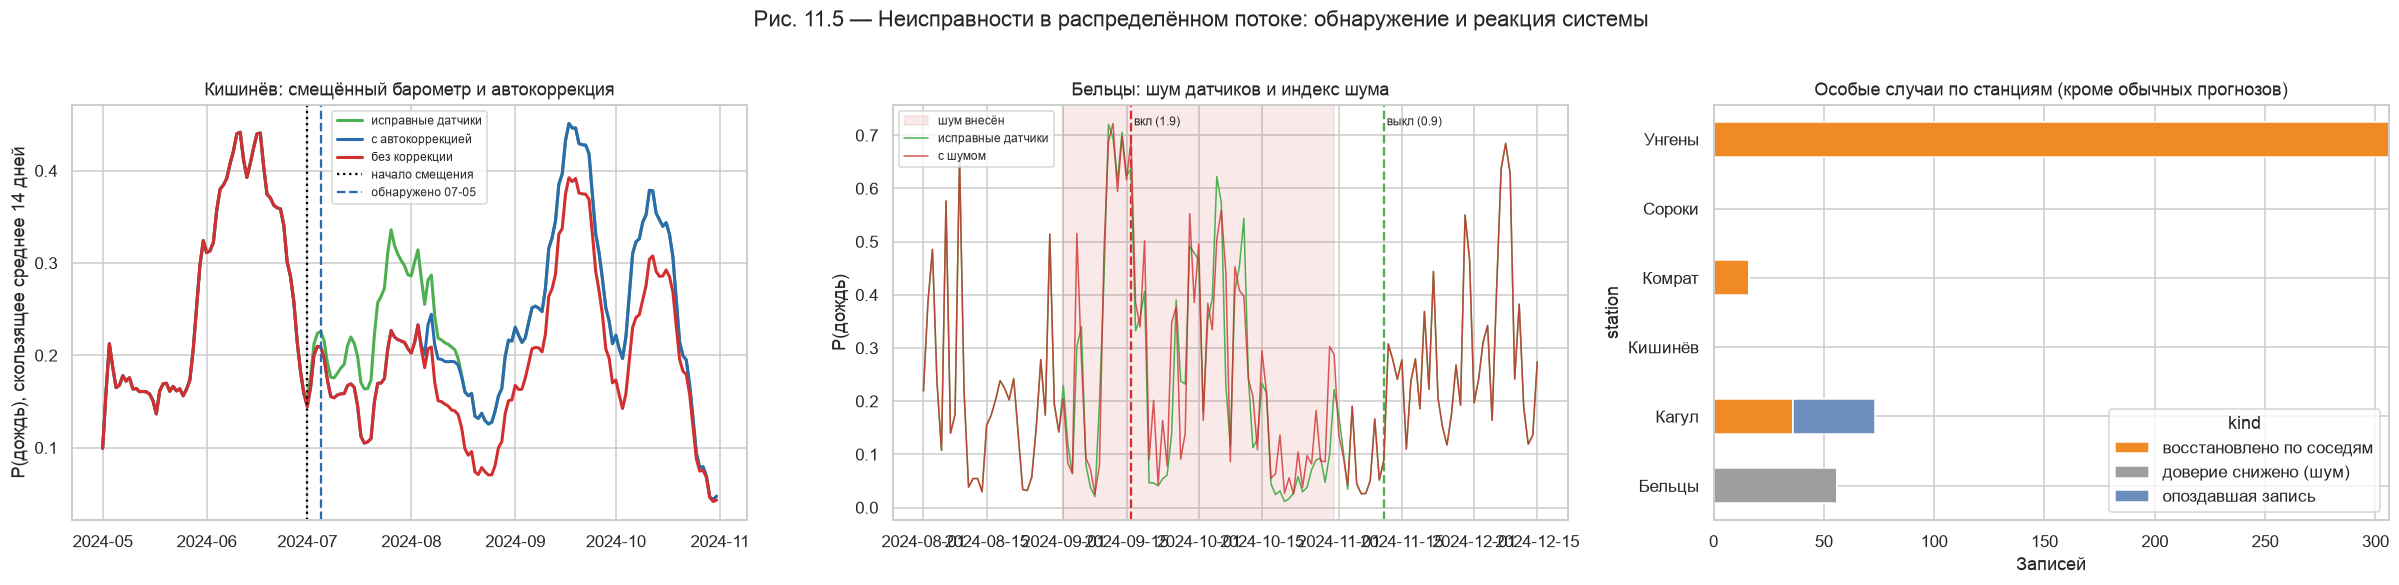

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(22, 5.2))
for res, name, col in [(clean, "исправные датчики", "#4CAF50"), (faults, "с автокоррекцией", "#2B6CB0"), (nocorr, "без коррекции", "#D32F2F")]:
    f = res["forecasts"]; f = f[(f.station == "chisinau") & (f.date >= "2024-05-01") & (f.date <= "2024-10-31") & f.p_rain.notna()]
    axes[0].plot(pd.to_datetime(f.date), f.p_rain.rolling(14, min_periods=1).mean(), color=col, lw=2, label=name)
det = sens[(sens.station == "chisinau") & (sens.check_name == "барометр")]
axes[0].axvline(pd.Timestamp("2024-07-01"), color="black", ls=":", label="начало смещения")
if len(det): axes[0].axvline(pd.Timestamp(det.date.iloc[0]), color="#2B6CB0", ls="--", label=f"обнаружено {det.date.iloc[0][5:]}")
axes[0].set(ylabel="P(дождь), скользящее среднее 14 дней", title="Кишинёв: смещённый барометр и автокоррекция"); axes[0].legend(fontsize=8)
nz = sens[(sens.station == "balti") & (sens.check_name == "шум")]
axes[1].axvspan(pd.Timestamp("2024-09-01"), pd.Timestamp("2024-10-31"), color="#D32F2F", alpha=0.1, label="шум внесён")
for _, r in nz.iterrows():
    axes[1].axvline(pd.Timestamp(r.date), color="#D32F2F" if "шумят" in r.message else "#4CAF50", ls="--")
    axes[1].text(pd.Timestamp(r.date), 0.95, f" {'вкл' if 'шумят' in r.message else 'выкл'} ({r.value:.1f})", fontsize=8, transform=axes[1].get_xaxis_transform())
b = faults["forecasts"]; b = b[(b.station == "balti") & (b.date >= "2024-08-01") & (b.date <= "2024-12-15") & b.p_rain.notna()]
bc = clean["forecasts"]; bc = bc[(bc.station == "balti") & (bc.date >= "2024-08-01") & (bc.date <= "2024-12-15") & bc.p_rain.notna()]
axes[1].plot(pd.to_datetime(bc.date), bc.p_rain, color="#4CAF50", lw=1, label="исправные датчики")
axes[1].plot(pd.to_datetime(b.date), b.p_rain, color="#D32F2F", lw=1, alpha=0.8, label="с шумом")
axes[1].set(ylabel="P(дождь)", title="Бельцы: шум датчиков и индекс шума"); axes[1].legend(fontsize=8, loc="upper left")
st_counts = faults["forecasts"].query("date >= '2024-01-01'").assign(
    kind=lambda d: np.select([d.status.str.contains("дополнено"), d.status.str.contains("опоздавш"), d.status.str.contains("шум"),
                              d.status.str.startswith("нет") | d.status.str.startswith("пропуск")],
                             ["восстановлено по соседям", "опоздавшая запись", "доверие снижено (шум)", "без прогноза"], "обычный прогноз"))
cnt = st_counts.groupby(["station", "kind"]).size().unstack(fill_value=0).drop(columns="обычный прогноз", errors="ignore")
cnt.rename(index=RU_ST).plot.barh(stacked=True, ax=axes[2], color=["#F08A24", "#9E9E9E", "#6C8EBF", "#8E44AD"][:cnt.shape[1]])
axes[2].set(xlabel="Записей", title="Особые случаи по станциям (кроме обычных прогнозов)")
fig.suptitle("Рис. 11.5 — Неисправности в распределённом потоке: обнаружение и реакция системы", y=1.02)
plt.tight_layout(); save("fig_11_5_faults")

**Интерпретация (неисправности).**

**Калибровка (рис. 11.5а).** После выбора порога по данным ложных тревог шума на исправных датчиках нет: в чистом прогоне все прогнозы обычные, а в прогоне с неисправностями шум обнаружен **только у Бельц**, где он и был внесён.

**Обнаружение (рис. 11.5).**

| Неисправность | Внесена | Обнаружена | Как |
|---|---|---|---|
| барометр Кишинёва +6 гПа | 01.07.2024 | **05.07.2024** (через 5 дней), оценка **+6.0 гПа** | отклонение от медианы 5 соседей, 5 дней подряд, стабильное |
| шум 0.75σ в Бельцах | 01.09–31.10.2024 | **16.09** (индекс 1.9), снят **11.11** | недельная проверка индекса шума по 14 дням |
| опоздания Кагула (37 сообщений на 3 суток) | весь период | все 37 записей заменили восстановленные | восстановление по соседям, затем замена опоздавшей записью |
| потери Комрата (18 сообщений) | весь период | 18 неполных окон Spark | контроль полноты (`count` в окне — упражнение D) |
| Унгены без направления ветра | 01.03.2025 | каждая запись | поле берётся у соседей того же дня |

Итог: **все 4 386 записей получили прогноз**, 358 — с восстановлением по соседям.

**Эффект вмешательств (таблица выше).**
- **Автокоррекция барометра** возвращает уровень прогноза: средняя P(дождь) Кишинёва 0.225 (исправные датчики — 0.229, без коррекции — 0.192). Recall растёт с 0.629 до 0.707 — без коррекции было бы ≈ 10 пропущенных дождей больше за полтора года; ROC-AUC 0.789 против 0.779. F1 почти не меняется (0.495 против 0.498): «сухая» модель без коррекции реже тревожит, зато чуть точнее. Поэтому эффект неисправности надо мерить Recall и уровнем вероятности, а не только F1.
- **Шум в Бельцах** снижает ROC-AUC с 0.919 до 0.886 (F1 0.727 → 0.667, 61 день). Убрать случайный шум сдвигом нельзя, поэтому система **снижает доверие** (56 прогнозов помечены) и сообщает о неисправности.
- **Восстановление направления ветра Унген** по соседям качество не ухудшает: ROC-AUC 0.778 против 0.774 у исправной станции, F1 0.558 против 0.561.

**Watermark и ускоренное время.** Spark не отбросил ни одного из 37 сообщений, опоздавших на 3 суток, хотя watermark — 2 суток. При воспроизведении 10 суток в секунду одна микропачка Spark (≈ 1 с) охватывает около 10 суток, поэтому опоздавшая запись успевает в ту же пачку, что и «свежие». В реальном времени (сутки за сутки) эти записи были бы отброшены Spark. Значит, параметры watermark нужно задавать в **событийном** времени под реальный ритм станций, а проверять при реалистичной скорости.

---
# 3. Упражнения лекции (A–F)

Короткие прогоны (январь–апрель 2024, без неисправностей), меняется по одному параметру:
- **A — частота продюсера:** 0.2 с на сутки (30 сообщений/с от 6 станций) против 0.02 с (300 сообщений/с);
- **C — размер окна:** окна по 1 суткам против **скользящих 3 суток** (шаг 1 сутки); окна обработки 10 с против 30 с;
- **B** (станция перестаёт присылать поле) и **D** (новый агрегат «число сообщений» = полнота) — уже в прогоне с неисправностями;
- **E, F** (C = 0.1 против 10; L1 / L2 / ENet) — в разделе настройки (окно 4).

Окна 2 и 3 готовы за 6 с; запускаю 6 станций
Отправлено сообщений: 774 за 25.7 с
  Кишинёв : вовремя 129, с опозданием 0, потеряно 0
  Сороки  : вовремя 129, с опозданием 0, потеряно 0
  Бельцы  : вовремя 129, с опозданием 0, потеряно 0
  Унгены  : вовремя 129, с опозданием 0, потеряно 0
  Комрат  : вовремя 129, с опозданием 0, потеряно 0
  Кагул   : вовремя 129, с опозданием 0, потеряно 0
Готово за 62 с (Spark: код 0, тревоги: код 0). Последние строки журнала тревог:
Сервис тревог готов за 5.5 с (разделов назначено: 7)
Обработано: 775 записей станций, 129 региональных окон
[ex_slow] 73 с


Окна 2 и 3 готовы за 6 с; запускаю 6 станций
Отправлено сообщений: 774 за 2.6 с
  Кишинёв : вовремя 129, с опозданием 0, потеряно 0
  Сороки  : вовремя 129, с опозданием 0, потеряно 0
  Бельцы  : вовремя 129, с опозданием 0, потеряно 0
  Унгены  : вовремя 129, с опозданием 0, потеряно 0
  Комрат  : вовремя 129, с опозданием 0, потеряно 0
  Кагул   : вовремя 129, с опозданием 0, потеряно 0
Готово за 39 с (Spark: код 0, тревоги: код 0). Последние строки журнала тревог:
Сервис тревог готов за 5.5 с (разделов назначено: 7)
Обработано: 775 записей станций, 129 региональных окон
[ex_fast] 50 с


Окна 2 и 3 готовы за 6 с; запускаю 6 станций
Отправлено сообщений: 774 за 25.7 с
  Кишинёв : вовремя 129, с опозданием 0, потеряно 0
  Сороки  : вовремя 129, с опозданием 0, потеряно 0
  Бельцы  : вовремя 129, с опозданием 0, потеряно 0
  Унгены  : вовремя 129, с опозданием 0, потеряно 0
  Комрат  : вовремя 129, с опозданием 0, потеряно 0
  Кагул   : вовремя 129, с опозданием 0, потеряно 0
Готово за 62 с (Spark: код 0, тревоги: код 0). Последние строки журнала тревог:
Сервис тревог готов за 5.4 с (разделов назначено: 7)
Обработано: 775 записей станций, 131 региональных окон
[ex_window3] 73 с


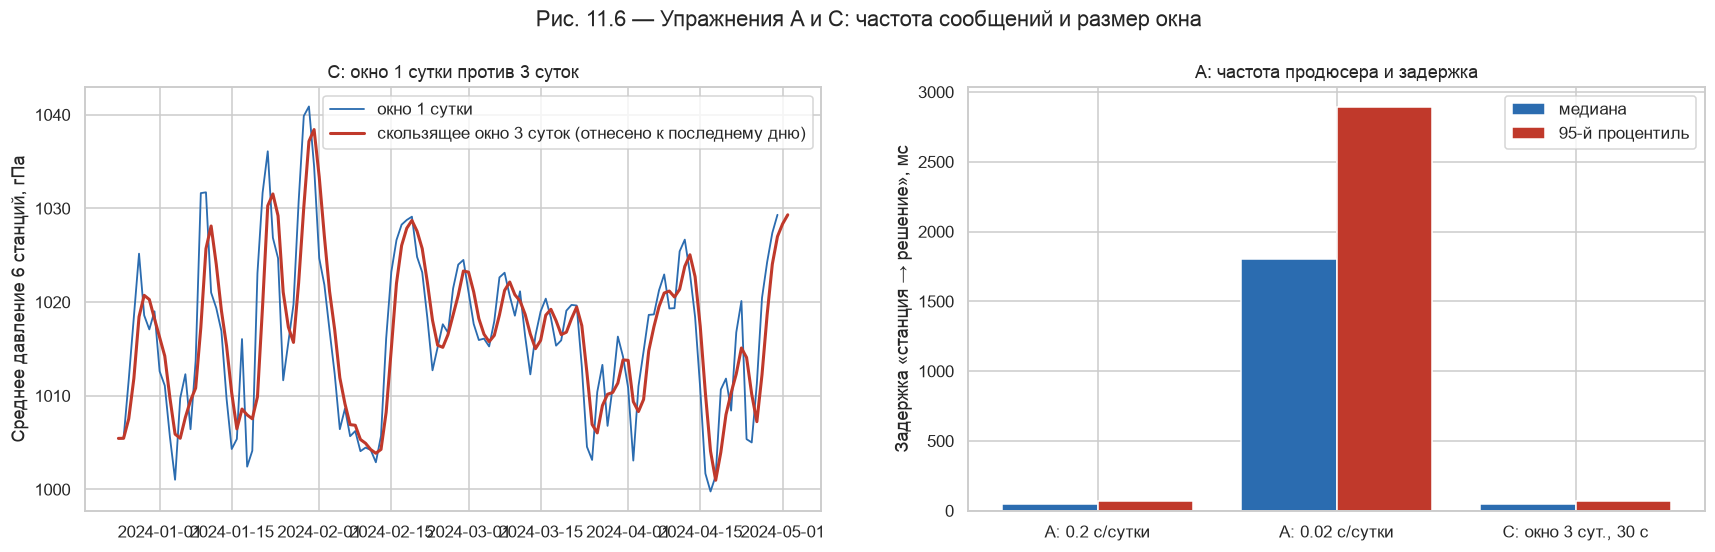

Сглаженность: ст. отклонение суточного изменения давления — окно 1 сутки 5.72 гПа, окно 3 суток 3.59 гПа


,Прогон,Сообщений/с (план),Обработано записей/с (факт),Сообщений в окне обработки (медиана),Окон обработки,Микропачек Spark,Строк в микропачке (медиана),"Длительность микропачки, мс","Задержка, мс (медиана)","Задержка, мс (95 %)",Региональных окон
0,A: 0.2 с/сутки,30.0,30.2,210.0,4,25,30.0,1006.0,50.0,73.0,129
1,A: 0.02 с/сутки,300.0,169.9,387.0,2,4,189.0,1179.5,1804.5,2890.0,129
2,"C: окно 3 сут., 30 с",30.0,30.2,387.0,2,25,30.0,1047.0,49.0,68.8,131


In [12]:
SHORT = ["--start", "2024-01-01", "--end", "2024-04-30"]
ex_slow = run("ex_slow", *SHORT, "--speed", "0.2")
ex_fast = run("ex_fast", *SHORT, "--speed", "0.02")
ex_w3 = run("ex_window3", *SHORT, "--speed", "0.2", "--window-days", "3", "--slide-days", "1", "--tp-window-sec", "30")
rows = []
for name, res, speed in [("A: 0.2 с/сутки", ex_slow, 0.2), ("A: 0.02 с/сутки", ex_fast, 0.02), ("C: окно 3 сут., 30 с", ex_w3, 0.2)]:
    f, tp, pr = res["forecasts"], res["throughput"], res["progress"]
    f = f[f.date >= "2024-01-01"]                                  # without the warm-up days
    per = tp.groupby("window_start").n_messages.sum()
    regp = pr[(pr["query"] == "regional") & (pr.input_rows > 0)]
    span = (f.processed_at_ms.max() - f.processed_at_ms.min()) / 1000
    rows.append({"Прогон": name, "Сообщений/с (план)": 6 / speed, "Обработано записей/с (факт)": len(f) / span,
                 "Сообщений в окне обработки (медиана)": per.median(),
                 "Окон обработки": len(per), "Микропачек Spark": len(regp), "Строк в микропачке (медиана)": regp.input_rows.median(),
                 "Длительность микропачки, мс": regp.batch_ms.median(), "Задержка, мс (медиана)": f.latency_ms.median(),
                 "Задержка, мс (95 %)": f.latency_ms.quantile(0.95), "Региональных окон": len(res["spark_regional"])})
ex_tbl = pd.DataFrame(rows)
r1 = ex_slow["spark_regional"].assign(d=lambda d: pd.to_datetime(d.window_start)).set_index("d").pressure_mean
r3 = ex_w3["spark_regional"].assign(d=lambda d: pd.to_datetime(d.window_start) + pd.Timedelta(days=2)).set_index("d").pressure_mean
fig, axes = plt.subplots(1, 2, figsize=(19, 5))
axes[0].plot(r1.index, r1, color="#2B6CB0", lw=1.2, label="окно 1 сутки")
axes[0].plot(r3.index, r3, color="#C0392B", lw=2, label="скользящее окно 3 суток (отнесено к последнему дню)")
axes[0].set(ylabel="Среднее давление 6 станций, гПа", title="C: окно 1 сутки против 3 суток"); axes[0].legend()
x = np.arange(3)
axes[1].bar(x - 0.2, ex_tbl["Задержка, мс (медиана)"], 0.4, color="#2B6CB0", label="медиана")
axes[1].bar(x + 0.2, ex_tbl["Задержка, мс (95 %)"], 0.4, color="#C0392B", label="95-й процентиль")
axes[1].set_xticks(x); axes[1].set_xticklabels(ex_tbl["Прогон"]); axes[1].set(ylabel="Задержка «станция → решение», мс", title="A: частота продюсера и задержка")
axes[1].legend()
fig.suptitle("Рис. 11.6 — Упражнения A и C: частота сообщений и размер окна", y=1.02)
save("fig_11_6_exercises")
print(f"Сглаженность: ст. отклонение суточного изменения давления — окно 1 сутки {r1.diff().std():.2f} гПа, окно 3 суток {r3.diff().std():.2f} гПа")
ex_tbl.round(1)

**Интерпретация (упражнения A–D).**

- **A — частота продюсера.**
  - При 30 сообщениях/с сервис обрабатывает 30.2 записи/с, медиана задержки **50 мс** (95-й процентиль 73 мс).
  - При 300 сообщениях/с — только **170 записей/с**: это предел сервиса (признаки + 3 модели + SHAP для каждой записи). Записи копятся в очереди Kafka (*consumer lag*), медиана задержки растёт до **1.8 с** (95-й процентиль 2.9 с). Spark при этом справляется: 4 микропачки по ~190 строк, ~1.2 с каждая.
  - Это ответ на вопрос лекции 4 *«что будет, если данные приходят быстрее, чем мы успеваем их обработать?»*: Kafka ничего не теряет — она хранит очередь, но решение запаздывает.
  - Лечится масштабированием потребителя (по экземпляру сервиса на группу разделов — у топика их 6) или более быстрой моделью (Elastic Net в 25 раз быстрее леса, ноутбук 09). Для 6 станций с одной записью в сутки запас — 7 порядков.
  - **Найдено при отладке:** первые прогоны показывали задержку 6 с даже при 30 сообщениях/с. Причина была в оркестраторе: он видел файлы готовности прошлого прогона и запускал станции раньше, чем группа потребителей получала разделы. После исправления (старые флаги удаляются, сервис готов только после назначения разделов) задержка — 50–60 мс.
- **B — станция перестала присылать поле** (Унгены, направление ветра): структура сообщения меняется (`null` в JSON), признаки направления ветра становятся NaN. Без вмешательства прогноз невозможен. Сервис берёт поле у соседей того же дня — качество не падает (ROC-AUC 0.778 против 0.774).
- **C — размер окна.** Скользящее окно 3 суток сглаживает региональное давление: стандартное отклонение суточного изменения падает с 5.72 до 3.59 гПа (−37 %). Но фронт с падением давления на 12–16 гПа за 3 дня в таком окне «расплывается» и виден на 1–2 дня позже. Для тревог (реакция на фронт) лучше 1 сутки, для трендов — 3. Окна обработки 30 с вместо 10 с дают более грубую картину пропускной способности (меньше окон) при той же нагрузке.
- **D — новый агрегат «число сообщений»** (`count` в окне) стал **контролем полноты**: 18 окон, где пришло меньше 6 сообщений, точно соответствуют 18 потерянным сообщениям Комрата.

---
# 4. Окно 4: настройка и вердикт — «простая модель против настроенной»

Лекция предлагает настраивать C, `l1_ratio` и окно и сравнивать простую модель с настроенной, а против переобучения на подборе использовать **кросс-валидацию**. Для временных рядов обычная перемешанная кросс-валидация недопустима (будущее учило бы прошлое), поэтому — `TimeSeriesSplit` (5 фолдов, каждый следующий год проверяется моделью, обученной на предыдущих) только на 2015–2022; тест 2024–2025 используется один раз.

Окно тоже становится параметром: это **признаки 5 соседних станций** (то, что считает Spark) — давление, влажность, облачность, доля дождливых сегодня и их изменение за окно W = 1, 3 или 7 суток.

In [13]:
tune = tuning_experiment(windows=(1, 3, 7))
res_t = tune["results"]
# the same distributed context for the Random Forest (does the main model profit too?)
from sklearn.base import clone
from verdict import regional_features
best_w = int(res_t[res_t["Модель"].str.contains("Настроенная") & res_t["Модель"].str.contains("соседи")]
             .sort_values("PR-AUC CV (2015–2022)", ascending=False).iloc[0]["Модель"].split("окно ")[1].split()[0])
reg = regional_features(best_w)
d2 = data.merge(reg, on="date", how="left").dropna()
feats2 = FEATURES + [c for c in reg.columns if c != "date"]
rows = []
for name, d, feats in [("Random Forest, 26 признаков станции", data, FEATURES), (f"Random Forest + соседи, окно {best_w} сут.", d2, feats2)]:
    tr_, va_, te_ = d[d.date.dt.year <= 2022], d[d.date.dt.year == 2023], d[d.date.dt.year >= 2024]
    m = clone(rf).fit(tr_[feats], tr_[TARGET])
    pv = m.predict_proba(va_[feats])[:, 1]; pt = m.predict_proba(te_[feats])[:, 1]
    grid = np.round(np.arange(0.05, 0.95, 0.01), 2)
    thr = float(grid[int(np.argmax([f1_score(va_[TARGET], pv >= g) for g in grid]))])
    rows.append({"Модель": name, "Параметры": "как в ноутбуке 02", "Признаков": len(feats), "PR-AUC валидация 2023": average_precision_score(va_[TARGET], pv),
                 "Порог": thr, "ROC-AUC тест": roc_auc_score(te_[TARGET], pt), "PR-AUC тест": average_precision_score(te_[TARGET], pt),
                 "F1 тест": f1_score(te_[TARGET], pt >= thr)})
    if "соседи" in name: rf_reg_imp = pd.Series(m.feature_importances_, index=feats)
res_all = pd.concat([res_t, pd.DataFrame(rows)], ignore_index=True)
res_all.round(3)

,Модель,Параметры,Признаков,PR-AUC CV (2015–2022),PR-AUC валидация 2023,Порог,ROC-AUC тест,PR-AUC тест,F1 тест,"Время подбора, с"
0,"Простая ENet (C = 1, α = 0.5), 26 признаков ст...","C = 1, α = 0.5",26,NaN,0.434,0.47,0.762,0.495,0.511,NaN
1,"Настроенная ENet (CV), 26 признаков станции","C = 0.03, α = 0.0",26,0.475,0.453,0.46,0.778,0.511,0.528,3.798
2,"Простая ENet (C = 1, α = 0.5), + соседи, окно ...","C = 1, α = 0.5",33,NaN,0.480,0.50,0.769,0.518,0.501,NaN
3,"Настроенная ENet (CV), + соседи, окно 1 сут.","C = 0.03, α = 0.0",33,0.505,0.470,0.51,0.783,0.534,0.530,10.082
4,"Настроенная ENet (CV), + соседи, окно 3 сут.","C = 0.1, α = 0.5",33,0.505,0.465,0.48,0.780,0.532,0.511,11.517
5,"Настроенная ENet (CV), + соседи, окно 7 сут.","C = 0.1, α = 0.5",33,0.506,0.476,0.47,0.784,0.538,0.522,10.970
6,"Random Forest, 26 признаков станции",как в ноутбуке 02,26,NaN,0.491,0.23,0.793,0.551,0.519,NaN
7,"Random Forest + соседи, окно 7 сут.",как в ноутбуке 02,33,NaN,0.506,0.26,0.803,0.571,0.543,NaN


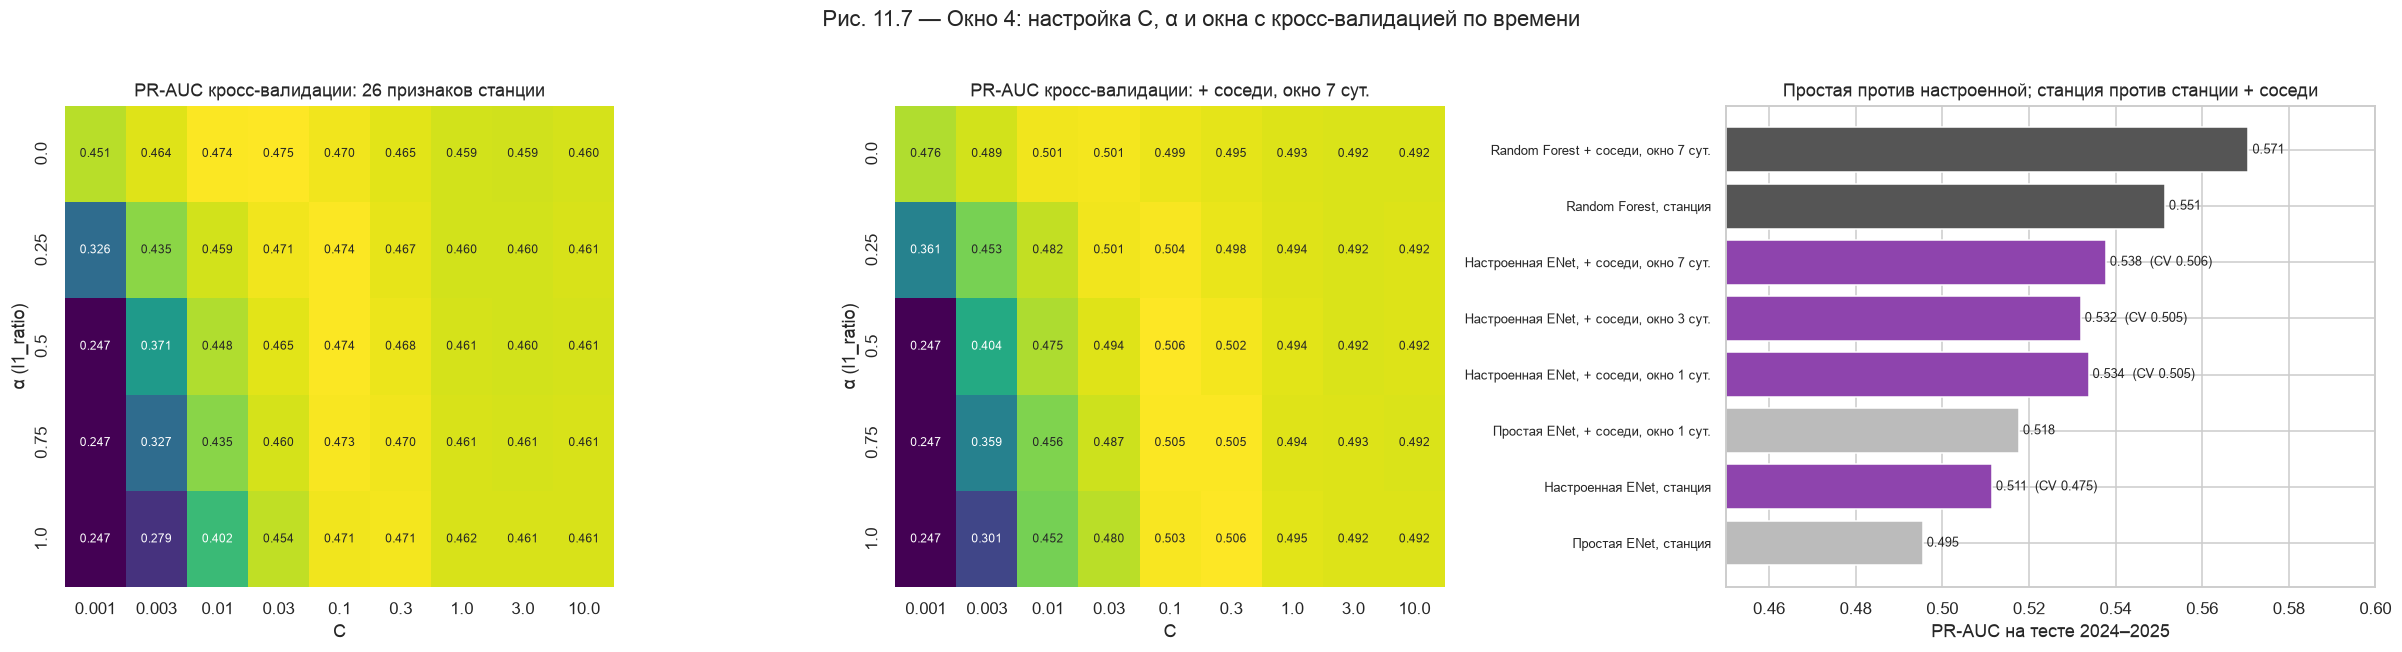

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(22, 5.8), gridspec_kw={"width_ratios": [1.1, 1.1, 1.3]})
for ax, tag in zip(axes[:2], ["26 признаков станции", f"+ соседи, окно {best_w} сут."]):
    cv = tune["cv"][tag].pivot(index="α", columns="C", values="PR-AUC CV")
    sns.heatmap(cv, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set(title=f"PR-AUC кросс-валидации: {tag}", xlabel="C", ylabel="α (l1_ratio)")
r = res_all.copy()
r["short"] = (r["Модель"].str.replace("Простая ENet (C = 1, α = 0.5)", "Простая ENet", regex=False)
              .str.replace("Настроенная ENet (CV)", "Настроенная ENet", regex=False).str.replace("26 признаков станции", "станция", regex=False))
cols = ["#BBBBBB" if "Простая" in s else ("#555555" if "Random" in s else "#8E44AD") for s in r["short"]]
axes[2].barh(r["short"], r["PR-AUC тест"], color=cols)
for y_, (v, cvs) in enumerate(zip(r["PR-AUC тест"], r["PR-AUC CV (2015–2022)"])):
    axes[2].text(v, y_, f" {v:.3f}" + (f"  (CV {cvs:.3f})" if pd.notna(cvs) else ""), va="center", fontsize=8.5)
axes[2].set(xlabel="PR-AUC на тесте 2024–2025", title="Простая против настроенной; станция против станции + соседи", xlim=(0.45, 0.6))
axes[2].tick_params(axis="y", labelsize=8.5)
fig.suptitle("Рис. 11.7 — Окно 4: настройка C, α и окна с кросс-валидацией по времени", y=1.02)
plt.tight_layout(); save("fig_11_7_tuning")

In [15]:
# E: C = 0.1 vs C = 10;  F: L1 vs L2 vs Elastic Net (C chosen by cross-validation for each α)
from regularization import make_model, coefficients
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
import shap
tr_, va_, te_ = data[data.date.dt.year <= 2022], data[data.date.dt.year == 2023], data[data.date.dt.year >= 2024]
cv_st = tune["cv"]["26 признаков станции"]
rows, imps = [], {}
for name, C, a in [("E: C = 0.1, α = 0.5", 0.1, 0.5), ("E: C = 10, α = 0.5", 10.0, 0.5)] + [
        (f"F: {lbl} (C по CV = {cv_st[cv_st['α'] == a].sort_values('PR-AUC CV').iloc[-1]['C']})",
         float(cv_st[cv_st["α"] == a].sort_values("PR-AUC CV").iloc[-1]["C"]), a) for lbl, a in [("L1", 1.0), ("L2", 0.0), ("ENet α = 0.5", 0.5)]]:
    m = make_model(C, a).fit(tr_[FEATURES], tr_[TARGET])
    w = coefficients(m); pt = m.predict_proba(te_[FEATURES])[:, 1]
    sv = shap.LinearExplainer(m[-1], shap.maskers.Independent(m[0].transform(tr_[FEATURES]), max_samples=500)).shap_values(m[0].transform(te_[FEATURES]))
    imp = pd.Series(np.abs(sv).mean(0), index=[FEATURE_NAMES_RU[f] for f in FEATURES]).sort_values(ascending=False)
    imps[name] = imp
    rows.append({"Вариант": name, "Ненулевых коэф.": int((np.abs(w) > 1e-10).sum()), "Норма весов": np.linalg.norm(w),
                 "Макс. |вес|": np.abs(w).max(), "PR-AUC тест": average_precision_score(te_[TARGET], pt),
                 "F1 тест (0.5)": f1_score(te_[TARGET], pt >= 0.5), "3 главных признака по SHAP": ", ".join(imp.index[:3])})
ef_tbl = pd.DataFrame(rows)
ef_tbl.round(3)

Background dataset has 2916 samples but max_samples=500. Subsampling to 500 samples for SHAP value computation. To use all samples, set max_samples=2916 when initializing the masker.


Background dataset has 2916 samples but max_samples=500. Subsampling to 500 samples for SHAP value computation. To use all samples, set max_samples=2916 when initializing the masker.


Background dataset has 2916 samples but max_samples=500. Subsampling to 500 samples for SHAP value computation. To use all samples, set max_samples=2916 when initializing the masker.


Background dataset has 2916 samples but max_samples=500. Subsampling to 500 samples for SHAP value computation. To use all samples, set max_samples=2916 when initializing the masker.


Background dataset has 2916 samples but max_samples=500. Subsampling to 500 samples for SHAP value computation. To use all samples, set max_samples=2916 when initializing the masker.


,Вариант,Ненулевых коэф.,Норма весов,Макс. |вес|,PR-AUC тест,F1 тест (0.5),3 главных признака по SHAP
0,"E: C = 0.1, α = 0.5",21,1.073,0.591,0.511,0.530,"Облачность, %, Давление, гПа, Дефицит точки ро..."
1,"E: C = 10, α = 0.5",26,2.446,1.788,0.490,0.508,"Дефицит точки росы, °C, Средняя влажность, %, ..."
2,F: L1 (C по CV = 0.3),24,1.323,0.736,0.505,0.520,"Дефицит точки росы, °C, Облачность, %, Давлени..."
3,F: L2 (C по CV = 0.03),26,0.995,0.539,0.511,0.531,"Облачность, %, Давление, гПа, Дефицит точки ро..."
4,F: ENet α = 0.5 (C по CV = 0.1),21,1.073,0.591,0.511,0.530,"Облачность, %, Давление, гПа, Дефицит точки ро..."


**Интерпретация (окно 4).**

- **Настройка помогает, но немного.** Простая ENet (C = 1, α = 0.5) даёт PR-AUC теста 0.495. Настроенная по кросс-валидации (C = 0.03, α = 0, т. е. L2) — 0.511 (+0.016).
  - Кросс-валидация на 2015–2022 оценила её в 0.475, валидация 2023 — в 0.453: оценки разных периодов различаются сильнее, чем модели между собой.
  - Это предупреждение лекции о «болезни настройки»: гнаться за третьим знаком на одном отрезке бессмысленно.
- **Окно W — не главное:** для соседей с окном 1, 3 и 7 суток PR-AUC кросс-валидации почти одинаков (0.505–0.506), на тесте 0.532–0.538.
- **Главное — данные распределённых источников.**
  - Признаки 5 соседних станций дают +0.023…+0.027 PR-AUC к настроенной ENet — больше, чем вся настройка.
  - **Основной Random Forest** с теми же признаками соседей улучшается: PR-AUC **0.551 → 0.571**, ROC-AUC 0.793 → 0.803, F1 0.519 → 0.543.
  - Атмосферный фронт приходит в Кишинёв от соседей: облачность и падение давления в Унгенах и Бельцах сегодня предсказывают дождь в Кишинёве завтра.
- **E — C = 0.1 против C = 10.** При C = 10 модель сложнее (26 ненулевых весов против 21, норма весов 2.45 против 1.07) и хуже (PR-AUC 0.490 против 0.511). Главными по SHAP становятся дефицит точки росы и влажность — артефакт связанных признаков из ноутбука 09, а не облачность и давление.
- **F — L1, L2, ENet** (C по кросс-валидации для каждого): PR-AUC 0.505 / 0.511 / 0.511, ненулевых весов 24 / 26 / 21. Интерпретируемее ENet (меньше признаков, главные — облачность и давление), стабильнее L2 (ноутбук 09).

---
# Ответы на вопросы лекции 5 и вердикт RTAP

### Упражнения лекции 5 (лист «Настройка в трилогии Kafka MD»)

| Упражнение | Вопрос | Ответ |
|---|---|---|
| A | Как меняется объём сообщений и что происходит со Spark и потребителем? | ×10 частоты → ×10 сообщений в окне; Spark — меньше, но крупнее микропачки; сервис справляется до ~170 записей/с, дальше очередь: задержка 50 мс → 1.8 с |
| B | Как меняется структура сообщения, какие признаки пропадают? | поле приходит как `null` → признаки направления ветра NaN; восстановление по соседям сохраняет качество |
| C | Окно 10 → 30 с (у нас 1 → 3 суток): стабильнее или медленнее? | и то и другое: на 37 % глаже, но фронт виден на 1–2 дня позже |
| D | Что значит агрегат «число сообщений», как его использовать? | полнота окна: 18 неполных окон = 18 потерянных сообщений; основание для восстановления и пометки |
| E | C = 0.1 → 10: проще или сложнее? | сложнее: 21 → 26 признаков, норма весов ×2.3, PR-AUC −0.021, «ложные» главные признаки |
| F | L1 / L2 / ENet: что интерпретируемее и стабильнее? | ENet интерпретируемее (21 признак), L2 стабильнее; качество почти равное |

**Что я узнал о настройке? Когда она полезна, когда излишня? Простота или качество?**
- Настройка полезна как **эксперимент понимания**: она показала, что сильный штраф убирает артефакты связанных признаков.
- Как погоня за метрикой она излишня: выигрыш 0.016 PR-AUC меньше разницы между оценками разных лет (0.453–0.511) и меньше вклада новых данных (+0.02–0.06).
- Для реальной системы я выбираю **простую модель + хорошие данные + контроль**: кросс-валидация по времени вместо одного разбиения, признаки соседей вместо тонкой настройки, калибровка порогов по исправным данным.

### Вопросы RTAP из листа рефлексии (последний вопрос каждого этапа)

1. **Как RTAP реагирует на прерывистый поток (источник то есть, то нет)?** — Spark считает число сообщений в окне (полнота). Сервис восстанавливает пропуск ≤ 2 суток по медиане ≥ 3 соседей, а опоздавшая запись заменяет восстановленную. Без достаточного числа соседей запись помечается, а региональное решение принимается по имеющимся голосам с пометкой «неполные данные».
2. **Какова роль признаков в коллективной агрегации?** — Spark превращает записи станций в региональные признаки (давление, доля дождливых, облачность). Они служат контекстом для решения (консенсус) и признаками модели: +0.02 PR-AUC у Random Forest.
3. **Как RTAP может использовать SHAP, чтобы сигнализировать о критическом состоянии?** — В каждой тревоге — три главных вклада SHAP. Типичный «критический» узор: сильное падение давления, осадки сегодня, восточный ветер. Если один признак даёт ≥ 30 % вклада (вердикт «Смещена», ноутбук 11), тревога особенно уязвима к неисправности именно этого датчика.
4. **Какие параметры настройки важны в RTAP?** — Сила регуляризации C, окно агрегации, порог тревоги (0.23) и порог консенсуса (4 из 6), watermark, пороги индекса шума и сдвига барометра. Все — **по данным**: индекс шума с порогом 1.4 давал ложные тревоги, после калибровки (1.8 / 1.3) — ни одной.
5. **Как RTAP разрешает конфликты между источниками?** — Большинством (≥ 4 из 6 для региональной тревоги) и сравнением каждого датчика с медианой соседей. Сдвиг признаётся только если он стабилен 5 дней (разброс < 1.5 гПа), иначе шум принимался бы за сдвиг.
6. **Какие фундаменты (bias, noise …) нужно отслеживать постоянно?** — Bias (смещение барометра относительно соседей), noise (индекс шума с сезонным эталоном), полноту (число сообщений), задержку и дрейф признаков (PSI, ноутбук 08).
7. **Как отличить тревогу от рекомендации?** — По согласию источников: жёлтый код Кишинёва при региональной тревоге верен в 42 % случаев, одиночный — в 11 %.
8. **Что такое «алгоритмический вердикт» в системе, которая слушает мир?** — Это не одна вероятность, а решение **с объяснением** (SHAP), **с уровнем доверия** (полнота, шум, вердикт «устойчива / смещена / искажена»), **с проверкой** по факту на следующий день и **с возвратом в систему** (коррекция барометра, переобучение). Лекция говорит: «вердикт возвращается в поток и делает систему мудрее» — у нас это обнаруженный сдвиг барометра, который исправляет все следующие прогнозы станции.

### Обнаружить → смоделировать → снизить (RTAP)

| Фактор | Обнаружили | Смоделировали | Снизили |
|---|---|---|---|
| Смещённый барометр | отклонение от соседей 5 дней подряд | +6 гПа с 01.07.2024 | автокоррекция: Recall 0.63 → 0.71, P 0.19 → 0.23 |
| Шум датчиков | индекс шума (калиброван) | 0.75σ на 4 датчиках | пометка «доверие снижено» + техническая тревога |
| Опоздания и потери | полнота окна, разрыв истории | 5 % опозданий, 2 % потерь | восстановление по соседям, замена опоздавшей записью |
| Пропавшее поле | `null` в сообщении | Унгены без направления ветра | поле от соседей: качество без потерь |
| Одиночный ложный сигнал | точность 11 % без поддержки соседей | — | региональная тревога только при ≥ 4 из 6 станций (точность 42 %) |
| Перегрузка потока | задержка 1.8 с при 300 сообщ./с (предел ~170/с) | ускоренное воспроизведение | масштабирование потребителя, быстрая модель (ENet) |

> **Вердикт RTAP:** Kafka «слушает» шесть станций и ничего не теряет. Spark превращает их в региональную картину, которая сама по себе улучшает прогноз. Решение объясняется (SHAP), проверяется соседями и само себя чинит при неисправности датчика. Главное, чему научил распределённый поток: **одна станция видит погоду, шесть станций видят фронт**.

In [16]:
out = ROOT / "data" / "processed"
res_all.to_csv(out / "rtap_tuning_results.csv", index=False)
impact.to_csv(out / "rtap_faults_impact.csv", index=False)
ex_tbl.to_csv(out / "rtap_exercises.csv", index=False)
m_clean.to_csv(out / "rtap_station_metrics.csv", index=False)
print("Сохранено: data/processed/rtap_*.csv; результаты прогонов — data/rtap/<прогон>/ (alerts.db, regional/, throughput/, progress.jsonl)")

Сохранено: data/processed/rtap_*.csv; результаты прогонов — data/rtap/<прогон>/ (alerts.db, regional/, throughput/, progress.jsonl)
